# Fine-Tuning & Evaluation: Llama 3.2 3B Instruct (Full 10k Official Split)
## Banking Customer Query Intent Classification (Banking77 Benchmark - 77 Intents)
### Literature-Matched Protocol: 10,003 Train / 0 Validation / 3,080 Test Queries (Seed = 42)
### Fault-Tolerant, Auto-Resumable Pipeline with Unsloth & QLoRA

- **Target Architecture:** `unsloth/Llama-3.2-3B-Instruct`
- **Quantization & PEFT Stack:** 4-bit NormalFloat QLoRA via **Unsloth (FastLanguageModel)**
- **Dataset:** Banking77 (`PolyAI/banking77`) — **Full Official Split (No Validation Split)**
  - **Train Instances:** **10,003** customer queries (complete official `train.csv`)
  - **Test Instances:** **3,080** customer queries (complete official `test.csv`)
  - **Random Seed:** `42`
- **Literature-Aligned QLoRA Hyperparameters:**
  - `num_train_epochs = 3`, `lora_r = 16`, `lora_alpha = 32`, `learning_rate = 2e-4`, `lr_scheduler_type = "cosine"`, `warmup_steps = 20`
- **Isolated Persistent Checkpoint Root:** `/content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42` (does not overwrite existing 9k/1k results)

## 1. System Environment & GPU Diagnostics
Checks available GPU hardware (Nvidia T4, P100, L4, or A100), VRAM allocation, and CUDA capability.


In [1]:
import torch
import os
import sys

print("=== SYSTEM & HARDWARE DIAGNOSTICS ===")
print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    total_vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    cuda_cap = torch.cuda.get_device_capability(0)
    print(f"GPU Device: {device_name}")
    print(f"Total VRAM: {total_vram_gb:.2f} GB")
    print(f"CUDA Capability: {cuda_cap}")
    print(f"bfloat16 Supported: {torch.cuda.is_bf16_supported()}")
else:
    print("[WARNING] No GPU detected! Please navigate to Runtime -> Change runtime type -> Select T4 GPU.")


=== SYSTEM & HARDWARE DIAGNOSTICS ===
Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU Device: Tesla T4
Total VRAM: 14.56 GB
CUDA Capability: (7, 5)
bfloat16 Supported: True


## 2. Accelerated Unsloth & Dependency Installation
Installs `unsloth` along with pre-compiled PEFT, acceleration, evaluation, and visualization tools (~1-2 minutes, zero source compilation).


In [2]:
# Install Unsloth and required PEFT / acceleration tools
# Expected runtime: ~1.5 to 2 minutes (pre-compiled binary wheels, zero source compilation)
!pip install "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install --no-deps trl peft accelerate bitsandbytes
!pip install datasets scikit-learn pandas gradio tabulate seaborn matplotlib huggingface_hub

print("All dependencies successfully installed!")


  Cloning https://github.com/unslothai/unsloth.git to /tmp/pip-install-lbcks3xq/unsloth_1d90fe405558481b8116a21306ce0635
  Running command git clone --filter=blob:none --quiet https://github.com/unslothai/unsloth.git /tmp/pip-install-lbcks3xq/unsloth_1d90fe405558481b8116a21306ce0635
  Resolved https://github.com/unslothai/unsloth.git to commit f49006976fa9575f8072ddd0f08e7f5142ecfaef
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 85.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 65.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 106.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 38.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 71.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 101.4 MB/s  0:00:00
  Created wheel for unsl

## 3. Persistent Checkpoint Root & Hub Authentication
Configures Hugging Face Hub authentication (seamlessly supporting Google Colab Secrets, Kaggle Secrets, or environment variables) and sets up persistent checkpoint directories to survive runtime resets.


In [3]:
import os
from huggingface_hub import login

# 1. Hugging Face Authentication
# Automatically retrieves token from Colab Secrets, Kaggle Secrets, or Environment Variables
HF_TOKEN = None

# Attempt 1: Google Colab Secrets (Key icon 🔑 in left sidebar)
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass

# Attempt 2: Kaggle Secrets (Add-ons -> Secrets)
if not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass

# Attempt 3: Environment Variable
if not HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")

if HF_TOKEN:
    login(token=HF_TOKEN)
    print("Hugging Face Hub authenticated successfully!")
else:
    print('⚠️ HF_TOKEN is required for gated model access. Please add your token under name HF_TOKEN in Google Colab Secrets (🔑 left sidebar) or Kaggle Secrets (Add-ons -> Secrets).')

# 2. Resumable Checkpoint Directory Setup
MODEL_SLUG = "llama_3_2_3b_banking_full10k_seed42"
CHECKPOINT_DIR = f"./{MODEL_SLUG}"

# If running on Kaggle, root checkpoints in /kaggle/working
if os.path.exists("/kaggle/working"):
    CHECKPOINT_DIR = f"/kaggle/working/{MODEL_SLUG}"

# If running on Google Colab, mount Google Drive for persistence across VM restarts
try:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = f"/content/drive/MyDrive/NLP_Checkpoints/{MODEL_SLUG}"
    print(f"[PERSISTENCE] Checkpoint root set to Google Drive: {CHECKPOINT_DIR}")
except Exception:
    print(f"[PERSISTENCE] Checkpoint root set to: {CHECKPOINT_DIR}")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
FINAL_ADAPTER_DIR = os.path.join(CHECKPOINT_DIR, "final_adapter")
os.makedirs(FINAL_ADAPTER_DIR, exist_ok=True)

Hugging Face Hub authenticated successfully!
Mounted at /content/drive
[PERSISTENCE] Checkpoint root set to Google Drive: /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42


## 4. Banking77 Official Full Dataset Pipeline (10,003 Train / 3,080 Test — No Validation Split)
Loads the **complete official PolyAI Banking77** benchmark splits (`10,003` train / `3,080` test) with **no validation slice**, matching standard literature protocols (Casanueva et al., 2020; Qi et al., 2021; Chinthakuntla et al., 2026).

In [4]:
import os
import json
import pandas as pd
from datasets import load_dataset, DatasetDict

# Complete 77 Intent taxonomy in authoritative order
BANKING77_LABELS = [
    "activate_my_card", "age_limit", "apple_pay_or_google_pay", "atm_support",
    "automatic_top_up", "balance_not_updated_after_bank_transfer",
    "balance_not_updated_after_cheque_or_cash_deposit", "beneficiary_not_allowed",
    "cancel_transfer", "card_about_to_expire", "card_acceptance", "card_arrival",
    "card_delivery_estimate", "card_linking", "card_not_working",
    "card_payment_fee_charged", "card_payment_not_recognised",
    "card_payment_wrong_exchange_rate", "card_swallowed", "cash_withdrawal_charge",
    "cash_withdrawal_not_recognised", "change_pin", "compromised_card",
    "contactless_not_working", "country_support", "declined_card_payment",
    "declined_cash_withdrawal", "declined_transfer",
    "direct_debit_payment_not_recognised", "disposable_card_limits",
    "edit_personal_details", "exchange_charge", "exchange_rate", "exchange_via_app",
    "extra_charge_on_statement", "failed_transfer", "fiat_currency_support",
    "get_disposable_virtual_card", "get_physical_card", "getting_spare_card",
    "getting_virtual_card", "lost_or_stolen_card", "lost_or_stolen_phone",
    "order_physical_card", "passcode_forgotten", "pending_card_payment",
    "pending_cash_withdrawal", "pending_top_up", "pending_transfer", "pin_blocked",
    "receiving_money", "Refund_not_showing_up", "request_refund",
    "reverted_card_payment?", "supported_cards_and_currencies", "terminate_account",
    "top_up_by_bank_transfer_charge", "top_up_by_card_charge",
    "top_up_by_cash_or_cheque", "top_up_failed", "top_up_limits", "top_up_reverted",
    "topping_up_by_card", "transaction_charged_twice", "transfer_fee_charged",
    "transfer_into_account", "transfer_not_received_by_recipient", "transfer_timing",
    "unable_to_verify_identity", "verify_my_identity", "verify_source_of_funds",
    "verify_top_up", "virtual_card_not_working", "visa_or_mastercard",
    "why_verify_identity", "wrong_amount_of_cash_received",
    "wrong_exchange_rate_for_cash_withdrawal"
]

id2label = {i: name for i, name in enumerate(BANKING77_LABELS)}
label2id = {name: i for i, name in id2label.items()}

print("Downloading official full PolyAI/banking77 splits (10,003 train / 3,080 test, no validation split)...")
try:
    hf_ds = load_dataset("PolyAI/banking77", trust_remote_code=True)
except Exception:
    try:
        hf_ds = load_dataset("banking77", trust_remote_code=True)
    except Exception:
        hf_ds = load_dataset(
            "csv",
            data_files={
                "train": "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv",
                "test": "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv"
            }
        )

raw_dataset = DatasetDict({
    "train": hf_ds["train"],  # Full 10,003 queries
    "test": hf_ds["test"]     # Full 3,080 queries
})

def standardize_features(batch):
    out = {}
    if "category" in batch and "label" not in batch:
        out["label"] = [label2id.get(cat, 0) for cat in batch["category"]]
    if "label" in batch and "category" not in batch:
        out["category"] = [id2label.get(lbl, "Unknown") for lbl in batch["label"]]
    return out

dataset = raw_dataset.map(standardize_features, batched=True)

train_dataset = dataset["train"]
test_dataset = dataset["test"]

assert len(train_dataset) == 10003, f"Expected 10,003 train queries, got {len(train_dataset)}"
assert len(test_dataset) == 3080, f"Expected 3,080 test queries, got {len(test_dataset)}"

print(f"\n=== OFFICIAL FULL BANKING77 DATASET LOADED (NO VALIDATION SPLIT) ===")
print(f"Training Queries   : {len(train_dataset):,}")
print(f"Validation Queries : 0 (Full official train split used)")
print(f"Testing Queries    : {len(test_dataset):,}")
print(f"Total Classes      : {len(BANKING77_LABELS)} Banking Intents")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'PolyAI/banking77' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'PolyAI/banking77' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

Map:   0%|          | 0/10003 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]


=== OFFICIAL FULL BANKING77 DATASET LOADED (NO VALIDATION SPLIT) ===
Training Queries   : 10,003
Validation Queries : 0 (Full official train split used)
Testing Queries    : 3,080
Total Classes      : 77 Banking Intents


## 5. Design of the 3 Experimental Prompting Methods

We tailor 3 distinct prompt formulations for Banking Intent Classification:

### 1. Baseline Prompting (Zero-Shot Direct Query Classification)
Directly prompts the model to classify the customer's query into one of the 77 intent classes without exemplars.

### 2. Few-Shot Prompting (In-Context Exemplar Learning)
Prepends 3 representative customer queries with their ground-truth intent labels to guide in-context reasoning.

### 3. Feature-Aware Prompting (Domain Entity & Operation Analysis)
Extracts structured financial inquiry signals:
- **Financial Entities Mentioned:** `card`, `account`, `transfer`, `atm`, `pin`, `apple pay`, `top up`, `exchange rate`, `cash`, `fee`, `refund`
- **Action / Problem Indicators:** `declined`, `pending`, `failed`, `lost`, `stolen`, `blocked`, `swallowed`, `activate`, `verify`, `charged twice`
- **Query Length Profile:** Word count


In [5]:
# Construct representative exemplar pool for Few-Shot prompting from the training set
few_shot_pool = [
    {
        "text": "I am still waiting on my new debit card to arrive after two weeks.",
        "label_name": "card_arrival"
    },
    {
        "text": "Why was an international transfer fee deducted from my account balance?",
        "label_name": "transfer_fee_charged"
    },
    {
        "text": "I lost my physical card yesterday and suspect someone is using it.",
        "label_name": "lost_or_stolen_card"
    }
]

def extract_banking_features(text):
    """Extracts structural financial entity mentions, transaction verbs, and query characteristics."""
    text_lower = text.lower()
    banking_entities = [
        e for e in [
            "card", "account", "transfer", "atm", "pin", "apple pay", "google pay",
            "top up", "exchange rate", "currency", "fee", "charge", "statement",
            "deposit", "cash", "cheque", "beneficiary", "identity", "passcode", "refund"
        ] if e in text_lower
    ]
    action_types = [
        a for a in [
            "declined", "pending", "failed", "cancel", "lost", "stolen", "blocked",
            "swallowed", "expired", "activate", "verify", "revert", "not working",
            "not received", "charged twice", "wrong amount"
        ] if a in text_lower
    ]
    word_count = len(text.split())
    return {
        "entities": banking_entities or ["general inquiry"],
        "actions": action_types or ["standard customer query"],
        "word_count": word_count
    }

def create_prompt(query_text, strategy="baseline"):
    """Constructs the prompt corresponding to one of the 3 experiment types."""
    if strategy == "baseline":
        return (
            "You are an expert banking customer service AI assistant. Classify the following customer query into its exact intent category from the Banking77 taxonomy.\n\n"
            f"Customer Query:\n\"\"\"\n{query_text.strip()}\n\"\"\"\n\n"
            "Provide ONLY the exact intent category name as your final output."
        )
    elif strategy == "few_shot":
        prompt = "You are an expert banking customer service AI assistant. Below are example customer queries and their correct intent categories:\n\n"
        for i, ex in enumerate(few_shot_pool, 1):
            prompt += f"### Example {i}:\nQuery: \"\"\"\n{ex['text'].strip()}\n\"\"\"\nIntent: {ex['label_name']}\n\n"
        prompt += (
            f"### Target Query to Classify:\nQuery: \"\"\"\n{query_text.strip()}\n\"\"\"\n"
            "Provide ONLY the exact intent category name as your final output.\nIntent:"
        )
        return prompt
    elif strategy == "feature_aware":
        feat = extract_banking_features(query_text)
        return (
            "You are an expert banking NLP assistant. Analyze the financial entities and action indicators present in the customer query, then predict its exact banking intent category from the Banking77 taxonomy.\n\n"
            f"Financial Entities Detected: {', '.join(feat['entities'])}\n"
            f"Action / Problem Indicators: {', '.join(feat['actions'])}\n"
            f"Query Length: {feat['word_count']} words\n\n"
            f"Customer Query:\n\"\"\"\n{query_text.strip()}\n\"\"\"\n\n"
            "Provide ONLY the exact intent category name as your final output."
        )
    else:
        raise ValueError(f"Unknown prompt strategy: {strategy}")

# Verification of Prompt Formulations
sample_query = test_dataset[0]["text"]
print("=== EXPERIMENT 1: BASELINE PROMPT ===")
print(create_prompt(sample_query, strategy="baseline"))
print("\n=== EXPERIMENT 2: FEW-SHOT PROMPT ===")
print(create_prompt(sample_query, strategy="few_shot"))
print("\n=== EXPERIMENT 3: FEATURE-AWARE PROMPT ===")
print(create_prompt(sample_query, strategy="feature_aware"))


=== EXPERIMENT 1: BASELINE PROMPT ===
You are an expert banking customer service AI assistant. Classify the following customer query into its exact intent category from the Banking77 taxonomy.

Customer Query:
"""
How do I locate my card?
"""

Provide ONLY the exact intent category name as your final output.

=== EXPERIMENT 2: FEW-SHOT PROMPT ===
You are an expert banking customer service AI assistant. Below are example customer queries and their correct intent categories:

### Example 1:
Query: """
I am still waiting on my new debit card to arrive after two weeks.
"""
Intent: card_arrival

### Example 2:
Query: """
Why was an international transfer fee deducted from my account balance?
"""
Intent: transfer_fee_charged

### Example 3:
Query: """
I lost my physical card yesterday and suspect someone is using it.
"""
Intent: lost_or_stolen_card

### Target Query to Classify:
Query: """
How do I locate my card?
"""
Provide ONLY the exact intent category name as your final output.
Intent:


## 6. Model Initialization via Unsloth (4-bit QLoRA)
Loads `unsloth/Llama-3.2-3B-Instruct` with fused RoPE kernels and 4-bit NormalFloat quantization.


In [6]:
import os
import torch
torch._dynamo.config.suppress_errors = True

from unsloth import FastLanguageModel

MODEL_NAME = "unsloth/Llama-3.2-3B-Instruct"
MAX_SEQ_LENGTH = 256  # 256 tokens empirically covers 100% of Banking77 prompts with zero truncation
LOAD_IN_4BIT = True

print(f"Loading {MODEL_NAME} with Unsloth 4-bit quantization...")
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LENGTH,
    load_in_4bit=LOAD_IN_4BIT,
    token=HF_TOKEN if HF_TOKEN else None,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"Successfully loaded {MODEL_NAME}!")


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1115 05:30:00.527000 417 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1115 05:30:00.673000 417 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


🦥 Unsloth Zoo will now patch everything to make training faster!
Loading unsloth/Llama-3.2-3B-Instruct with Unsloth 4-bit quantization...
==((====))==  Unsloth 2026.11.4: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Unsloth: Will load unsloth/Llama-3.2-3B-Instruct-unsloth-bnb-4bit as a legacy tokenizer.


Successfully loaded unsloth/Llama-3.2-3B-Instruct!


## 7. Fault-Tolerant Batched Evaluation, Hardware Profiling & Resumable Metrics Engine
Measures inference latency, peak GPU VRAM allocation, and precision/recall/F1 metrics across the 77-class taxonomy with auto-checkpointing.

In [7]:
import re
import time
import json
import os
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Configure evaluation sample limit (Set to None for the complete 3,080 test set)
EVAL_MAX_SAMPLES = None

def parse_prediction(generated_text, candidate_labels):
    """Extracts the exact intent category name from generated model text."""
    clean = generated_text.strip().strip('"').strip("'").strip()
    first_line = clean.split('\n')[0].strip()

    # 1. Exact match against candidate intent categories
    for label in candidate_labels:
        if first_line.lower() == label.lower():
            return label

    # 2. Substring word-boundary match on first line
    matched = []
    for label in candidate_labels:
        pat = r'\b' + re.escape(label.lower()) + r'\b'
        if re.search(pat, first_line.lower()):
            matched.append(label)
    if matched:
        return max(matched, key=len)

    # 3. Fallback search across generated output
    for label in candidate_labels:
        pat = r'\b' + re.escape(label.lower()) + r'\b'
        if re.search(pat, clean.lower()):
            matched.append(label)
    if matched:
        return max(matched, key=len)

    return "Unknown"

def evaluate_experiment(model, tokenizer, test_data, experiment_name, strategy="baseline", batch_size=32, max_samples=EVAL_MAX_SAMPLES):
    """Executes batched inference with automatic hardware profiling, checkpointing, and resumption."""
    cache_slug = experiment_name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("-", "_")
    cache_file = os.path.join(CHECKPOINT_DIR, f"{cache_slug}_metrics.json")
    preds_file = os.path.join(CHECKPOINT_DIR, f"{cache_slug}_predictions.json")
    partial_cache_file = os.path.join(CHECKPOINT_DIR, f"{cache_slug}_partial.json")

    # Check if already completed and cached
    if os.path.exists(cache_file):
        print(f"\n>>> [RESUMED FROM CACHE] {experiment_name} metrics found at '{cache_file}'. Loading instantly! <<<")
        with open(cache_file, "r") as f:
            cached_metrics = json.load(f)
        eval_time_str = cached_metrics.get("Eval Time (Formatted)", f"{cached_metrics.get('Eval Time (s)', 0.0):.1f}s")
        peak_vram = cached_metrics.get("Peak VRAM Allocated (GB)", 0.0)
        print(f"  -> {experiment_name} (Cached): Acc={cached_metrics['Accuracy']:.4f} | Macro-F1={cached_metrics['F1 (Macro)']:.4f} | Time={eval_time_str} | Peak VRAM={peak_vram:.2f} GB")
        return cached_metrics

    FastLanguageModel.for_inference(model)

    if max_samples:
        eval_items = test_data.select(range(min(len(test_data), max_samples)))
    else:
        eval_items = test_data

    y_true = []
    y_pred = []
    start_idx = 0
    accumulated_eval_time = 0.0

    # Check for partial intermediate cache (interrupted midway)
    if os.path.exists(partial_cache_file):
        try:
            with open(partial_cache_file, "r") as pf:
                partial_data = json.load(pf)
                y_true = partial_data.get("y_true", [])
                y_pred = partial_data.get("y_pred", [])
                accumulated_eval_time = partial_data.get("accumulated_eval_time", 0.0)
                start_idx = len(y_true)
                if start_idx < len(eval_items):
                    print(f"\n  [RESUME] Found partial progress for {experiment_name}: Resuming from query {start_idx:,} of {len(eval_items):,} (Previous Time: {accumulated_eval_time:.1f}s)...")
                else:
                    start_idx = 0
        except Exception:
            y_true, y_pred = [], []
            start_idx = 0
            accumulated_eval_time = 0.0

    if start_idx == 0:
        print(f"\n>>> Running: {experiment_name} [{strategy.upper()}] on {len(eval_items):,} test queries (Batch Size = {batch_size}) <<<")

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    eval_start_time = time.time()

    for i in range(start_idx, len(eval_items), batch_size):
        batch = eval_items[i : i + batch_size]
        prompts = [create_prompt(t, strategy=strategy) for t in batch["text"]]
        true_labels = [id2label[l] for l in batch["label"]]

        # Build chat template inputs
        formatted_inputs = []
        for p in prompts:
            messages = [{"role": "user", "content": p}]
            formatted = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
            formatted_inputs.append(formatted)

        inputs = tokenizer(
            formatted_inputs,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_SEQ_LENGTH
        ).to("cuda")

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=15,
                temperature=0.1,
                do_sample=False,
                use_cache=True
            )

        for j, out_tokens in enumerate(outputs):
            in_len = inputs["input_ids"][j].shape[0]
            gen_text = tokenizer.decode(out_tokens[in_len:], skip_special_tokens=True)
            pred_label = parse_prediction(gen_text, BANKING77_LABELS)

            y_true.append(true_labels[j])
            y_pred.append(pred_label)

        # Save partial progress every 250 queries
        if len(y_true) % 250 == 0 or len(y_true) >= len(eval_items):
            current_elapsed = accumulated_eval_time + (time.time() - eval_start_time)
            with open(partial_cache_file, "w") as pf:
                json.dump({"y_true": y_true, "y_pred": y_pred, "accumulated_eval_time": current_elapsed}, pf)

        if (i + batch_size) % 200 == 0 or (i + batch_size) >= len(eval_items):
            print(f"  Processed {min(i + batch_size, len(eval_items)):,}/{len(eval_items):,} queries...", end="\r")
    print()

    eval_duration_sec = round(accumulated_eval_time + (time.time() - eval_start_time), 2)
    eval_duration_min = round(eval_duration_sec / 60, 2)
    eval_time_fmt = time.strftime("%H:%M:%S", time.gmtime(eval_duration_sec))
    peak_vram_alloc = round(torch.cuda.max_memory_allocated() / (1024 ** 3), 3) if torch.cuda.is_available() else 0.0
    peak_vram_res = round(torch.cuda.max_memory_reserved() / (1024 ** 3), 3) if torch.cuda.is_available() else 0.0

    # Calculate Required Metrics
    acc = accuracy_score(y_true, y_pred)
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

    metrics = {
        "Experiment": experiment_name,
        "Strategy": strategy,
        "Accuracy": acc,
        "Precision (Weighted)": p_w,
        "Recall (Weighted)": r_w,
        "F1 (Weighted)": f1_w,
        "Precision (Macro)": p_m,
        "Recall (Macro)": r_m,
        "F1 (Macro)": f1_m,
        "Eval Time (s)": eval_duration_sec,
        "Eval Time (min)": eval_duration_min,
        "Eval Time (Formatted)": eval_time_fmt,
        "Peak VRAM Allocated (GB)": peak_vram_alloc,
        "Peak VRAM Reserved (GB)": peak_vram_res,
    }

    # Save completed metrics cache & remove partial progress file
    with open(preds_file, "w") as pf:
        json.dump({"y_true": y_true, "y_pred": y_pred}, pf)
    with open(cache_file, "w") as f:
        json.dump(metrics, f, indent=2)
    if os.path.exists(partial_cache_file):
        try:
            os.remove(partial_cache_file)
        except Exception:
            pass

    print(f"  -> {experiment_name} Results: Acc={acc:.4f} | Prec(W)={p_w:.4f} | Rec(W)={r_w:.4f} | F1(W)={f1_w:.4f} | Macro-F1={f1_m:.4f}")
    print(f"     [HARDWARE & RUNTIME] Time: {eval_time_fmt} ({eval_duration_sec:.1f}s) | Peak VRAM: {peak_vram_alloc:.2f} GB (Allocated), {peak_vram_res:.2f} GB (Reserved)")
    return metrics


## 8. Pre-Training Evaluation Phase (All 3 Experiments)
Evaluates the base pre-trained model on the 3,080 Banking77 test split across:
1. **Experiment 1:** Pre-Train Baseline (Zero-Shot)
2. **Experiment 2:** Pre-Train Few-Shot (In-Context)
3. **Experiment 3:** Pre-Train Feature-Aware (Domain Signals)

*(If any evaluation was previously completed, it will instantly load from cache)*


In [8]:
master_results = {}

print("=======================================================================")
print("PRE-TRAINING BENCHMARK EVALUATIONS (BASELINE, FEW-SHOT, FEATURE-AWARE)")
print("=======================================================================")

# Experiment 1: Pre-Train Baseline
master_results["Pre-Train (Baseline)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Pre-Train Baseline",
    strategy="baseline",
    batch_size=32
)

# Experiment 2: Pre-Train Few-Shot
master_results["Pre-Train (Few-Shot)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Pre-Train Few-Shot",
    strategy="few_shot",
    batch_size=16
)

# Experiment 3: Pre-Train Feature-Aware
master_results["Pre-Train (Feature-Aware)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Pre-Train Feature-Aware",
    strategy="feature_aware",
    batch_size=32
)

pre_eval_total_sec = sum(master_results[k].get("Eval Time (s)", 0.0) for k in master_results if "Pre-Train" in k)
pre_eval_peak_vram = max((master_results[k].get("Peak VRAM Allocated (GB)", 0.0) for k in master_results if "Pre-Train" in k), default=0.0)
print("\n" + "="*80)
print(f"[PRE-TRAIN PHASE SUMMARY] Total Time: {time.strftime('%H:%M:%S', time.gmtime(pre_eval_total_sec))} ({pre_eval_total_sec:.1f}s) | Peak VRAM: {pre_eval_peak_vram:.2f} GB")
print("="*80 + "\n")


Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


PRE-TRAINING BENCHMARK EVALUATIONS (BASELINE, FEW-SHOT, FEATURE-AWARE)

>>> Running: Pre-Train Baseline [BASELINE] on 3,080 test queries (Batch Size = 32) <<<


Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

... (11 outputs left out)

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  Processed 3,080/3,080 queries...
  -> Pre-Train Feature-Aware Results: Acc=0.0023 | Prec(W)=0.0260 | Rec(W)=0.0023 | F1(W)=0.0042 | Macro-F1=0.0041
     [HARDWARE & RUNTIME] Time: 00:03:43 (223.2s) | Peak VRAM: 6.20 GB (Allocated), 8.19 GB (Reserved)

[PRE-TRAIN PHASE SUMMARY] Total Time: 00:11:45 (705.3s) | Peak VRAM: 6.20 GB



## 9. QLoRA Adapter Configuration & Multi-Strategy SFT Preparation
- Attaches Low-Rank Adaptation (LoRA) matrices ($r=16, lpha=16$) to all linear projections (`q, k, v, o, gate, up, down`).
- Formats the 9,003 training instances using **Multi-Strategy Conditioning**:
  - ~3,001 instances formatted with **Baseline** prompts
  - ~3,001 instances formatted with **Few-Shot** prompts
  - ~3,001 instances formatted with **Feature-Aware** prompts


In [9]:
print("=======================================================================")
print("QLORA ADAPTER CONFIGURATION & TRAINING PREPARATION")
print("=======================================================================")

# Configure LoRA Adapter
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha=32,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing=True,
    random_state=42,
)

print("LoRA Adapter successfully attached!")
model.print_trainable_parameters()

# Multi-Strategy SFT Dataset Formatting
def format_multi_strategy_chat(examples, indices):
    texts = []
    strategies = ["baseline", "few_shot", "feature_aware"]
    for idx, text, label_id in zip(indices, examples["text"], examples["label"]):
        strat = strategies[idx % len(strategies)]
        category = id2label[label_id]
        user_prompt = create_prompt(text, strategy=strat)
        messages = [
            {"role": "user", "content": user_prompt},
            {"role": "assistant", "content": category}
        ]
        formatted = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
        texts.append(formatted)
    return {"text": texts}

print(f"Formatting {len(train_dataset):,} training queries across all 3 strategies...")
train_formatted = train_dataset.map(format_multi_strategy_chat, with_indices=True, batched=True)

print("Sample Formatted Chat Instance:")
print(train_formatted[0]["text"][:400])

QLORA ADAPTER CONFIGURATION & TRAINING PREPARATION


Unsloth 2026.11.4 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (LlamaDecoderLayer).
LoRA Adapter successfully attached!
trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511
Formatting 10,003 training queries across all 3 strategies...


Map:   0%|          | 0/10003 [00:00<?, ? examples/s]

Sample Formatted Chat Instance:
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 15 Nov 2026

<|eot_id|><|start_header_id|>user<|end_header_id|>

You are an expert banking customer service AI assistant. Classify the following customer query into its exact intent category from the Banking77 taxonomy.

Customer Query:
"""
I am still waiting on my card?
"""

Provide ONLY


## 10. Resumable QLoRA Supervised Fine-Tuning Execution & Hardware Profiling
Executes 4-bit QLoRA fine-tuning with automatic peak VRAM monitoring, training wall-time tracking, and intermediate step checkpointing.

In [10]:
from trl import SFTTrainer
from transformers import TrainingArguments
from transformers.trainer_utils import get_last_checkpoint
import time

training_stats_file = os.path.join(CHECKPOINT_DIR, "training_hardware_and_time.json")
training_hardware_stats = {}

# Check if final fine-tuned adapter already exists on disk / Drive
if os.path.exists(os.path.join(FINAL_ADAPTER_DIR, "adapter_config.json")):
    print("\n" + "="*80)
    print(f"[RESUME] Final fine-tuned adapter found at '{FINAL_ADAPTER_DIR}'!")
    print("Skipping training phase entirely and loading fine-tuned weights for evaluation.")
    print("="*80)
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=FINAL_ADAPTER_DIR,
        max_seq_length=MAX_SEQ_LENGTH,
        load_in_4bit=LOAD_IN_4BIT,
    )
    if os.path.exists(training_stats_file):
        with open(training_stats_file, "r") as f:
            training_hardware_stats = json.load(f)
        print(f"Loaded existing training hardware metrics: Time = {training_hardware_stats.get('training_time_formatted')} | Peak VRAM = {training_hardware_stats.get('peak_vram_allocated_gb', 0.0):.2f} GB")
else:
    training_args = TrainingArguments(
        output_dir=CHECKPOINT_DIR,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=2,
        warmup_steps=20,
        num_train_epochs=3,  # 3 epochs per Chinthakuntla et al. (2026) & QLoRA best practices on 10k queries
        learning_rate=2e-4,
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
        logging_steps=25,
        optim="adamw_8bit",
        weight_decay=0.01,
        lr_scheduler_type="cosine",
        seed=42,
        save_strategy="steps",
        save_steps=250,      # Saves checkpoint every 250 steps
        save_total_limit=2,  # Retains last 2 checkpoints to preserve disk space
        report_to="none"
    )

    import torch
    torch._dynamo.config.suppress_errors = True

    trainer = SFTTrainer(
        model=model,
        tokenizer=tokenizer,
        train_dataset=train_formatted,
        dataset_text_field="text",
        max_seq_length=MAX_SEQ_LENGTH,
        dataset_num_proc=2,
        packing=False,
        args=training_args,
    )

    # Check for existing intermediate checkpoint to resume
    last_ckpt = get_last_checkpoint(CHECKPOINT_DIR) if os.path.exists(CHECKPOINT_DIR) else None

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    train_start_time = time.time()

    if last_ckpt is not None:
        print("\n" + "="*80)
        print(f"[RESUME] Resuming training from intermediate checkpoint: '{last_ckpt}'")
        print("="*80)
        trainer_stats = trainer.train(resume_from_checkpoint=last_ckpt)
    else:
        print("\n" + "="*80)
        print("Starting QLoRA Fine-Tuning on Banking77 queries...")
        print("="*80)
        trainer_stats = trainer.train()

    train_duration_sec = round(time.time() - train_start_time, 2)
    train_duration_min = round(train_duration_sec / 60, 2)
    train_time_fmt = time.strftime("%H:%M:%S", time.gmtime(train_duration_sec))
    peak_vram_alloc = round(torch.cuda.max_memory_allocated() / (1024 ** 3), 3) if torch.cuda.is_available() else 0.0
    peak_vram_res = round(torch.cuda.max_memory_reserved() / (1024 ** 3), 3) if torch.cuda.is_available() else 0.0

    training_hardware_stats = {
        "model_name": MODEL_NAME,
        "model_slug": MODEL_SLUG,
        "training_time_seconds": train_duration_sec,
        "training_time_minutes": train_duration_min,
        "training_time_formatted": train_time_fmt,
        "peak_vram_allocated_gb": peak_vram_alloc,
        "peak_vram_reserved_gb": peak_vram_res,
        "epochs": 3,
        "batch_size_effective": 8,
        "seed": 42
    }
    with open(training_stats_file, "w") as f:
        json.dump(training_hardware_stats, f, indent=2)

    print("\n" + "="*80)
    print(f"[COMPLETE] Fine-Tuning Complete in {train_duration_min:.2f} minutes ({train_duration_sec:.1f}s | {train_time_fmt}).")
    print(f"   [HARDWARE] Training Peak VRAM Allocated: {peak_vram_alloc:.2f} GB | Reserved: {peak_vram_res:.2f} GB")
    print("="*80)

    print("Fine-tuning completed successfully! Saving final adapter...")
    model.save_pretrained(FINAL_ADAPTER_DIR)
    tokenizer.save_pretrained(FINAL_ADAPTER_DIR)
    print(f"Saved final fine-tuned adapter to '{FINAL_ADAPTER_DIR}'.")


Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/10003 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.

Starting QLoRA Fine-Tuning on Banking77 queries...


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 10,003 | Num Epochs = 3 | Total steps = 3,753
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 24,313,856 of 3,237,063,680 (0.75% trained)


Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.


Step,Training Loss
25,2.327909
50,0.397208
75,0.270209
100,0.304286
125,0.263902
150,0.267839
175,0.285670
200,0.257582
225,0.240572
250,0.261417


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/checkpoint-250/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/checkpoint-500/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/checkpoint-750/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/checkpoint-1000/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/checkpoint-1250/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/checkpoint-1500/tokenizer_config.json.
Unsloth: Rest


[COMPLETE] Fine-Tuning Complete in 121.37 minutes (7281.9s | 02:01:21).
   [HARDWARE] Training Peak VRAM Allocated: 2.94 GB | Reserved: 3.23 GB
Fine-tuning completed successfully! Saving final adapter...


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/final_adapter/tokenizer_config.json.


Saved final fine-tuned adapter to '/content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/final_adapter'.


## 11. Post-Training Evaluation Phase (All 3 Experiments)
Evaluates the fine-tuned model on the 3,080 test split across:
1. **Experiment 1:** Post-Train Baseline (Zero-Shot)
2. **Experiment 2:** Post-Train Few-Shot (In-Context)
3. **Experiment 3:** Post-Train Feature-Aware (Domain Signals)

*(Uses the same caching and batch-level recovery system; skips already-completed evaluations)*


In [11]:
print("=======================================================================")
print("POST-TRAINING BENCHMARK EVALUATIONS (BASELINE, FEW-SHOT, FEATURE-AWARE)")
print("=======================================================================")

FastLanguageModel.for_inference(model)

# Experiment 1: Post-Train Baseline
master_results["Post-Train (Baseline)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Post-Train Baseline",
    strategy="baseline",
    batch_size=32
)

# Experiment 2: Post-Train Few-Shot
master_results["Post-Train (Few-Shot)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Post-Train Few-Shot",
    strategy="few_shot",
    batch_size=16
)

# Experiment 3: Post-Train Feature-Aware
master_results["Post-Train (Feature-Aware)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Post-Train Feature-Aware",
    strategy="feature_aware",
    batch_size=32
)

post_eval_total_sec = sum(master_results[k].get("Eval Time (s)", 0.0) for k in master_results if "Post-Train" in k)
post_eval_peak_vram = max((master_results[k].get("Peak VRAM Allocated (GB)", 0.0) for k in master_results if "Post-Train" in k), default=0.0)
print("\n" + "="*80)
print(f"[POST-TRAIN PHASE SUMMARY] Total Time: {time.strftime('%H:%M:%S', time.gmtime(post_eval_total_sec))} ({post_eval_total_sec:.1f}s) | Peak VRAM: {post_eval_peak_vram:.2f} GB")
print("="*80 + "\n")


Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


POST-TRAINING BENCHMARK EVALUATIONS (BASELINE, FEW-SHOT, FEATURE-AWARE)

>>> Running: Post-Train Baseline [BASELINE] on 3,080 test queries (Batch Size = 32) <<<


Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

... (11 outputs left out)

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  Processed 3,080/3,080 queries...
  -> Post-Train Feature-Aware Results: Acc=0.9380 | Prec(W)=0.9410 | Rec(W)=0.9380 | F1(W)=0.9386 | Macro-F1=0.9266
     [HARDWARE & RUNTIME] Time: 00:03:41 (221.8s) | Peak VRAM: 6.39 GB (Allocated), 7.12 GB (Reserved)

[POST-TRAIN PHASE SUMMARY] Total Time: 00:11:56 (716.7s) | Peak VRAM: 6.39 GB



## 12. Master Metrics Comparison Matrix, Hardware Footprint & Quantitative Gains ($\Delta$)
Aggregates all 6 experimental evaluations across **Accuracy, Precision, Recall, F1 Score, Latency, and GPU VRAM** into unified comparison tables and persists structured summaries to CSV and JSON.


MASTER EVALUATION REPORT: unsloth/Llama-3.2-3B-Instruct on Banking77 (10,003 Train / 0 Val / 3,080 Test | Seed 42)
╒════════════════════════════╤════════════════╤═════════════════════╤══════════════════╤════════════════════╤════════════════╤═════════════════╤═════════════╤══════════════════╕
│ Experiment Run             │   Accuracy (%) │   Precision (W) (%) │   Recall (W) (%) │   F1 Score (W) (%) │   Macro F1 (%) │   Eval Time (s) │ Eval Time   │   Peak VRAM (GB) │
╞════════════════════════════╪════════════════╪═════════════════════╪══════════════════╪════════════════════╪════════════════╪═════════════════╪═════════════╪══════════════════╡
│ Pre-Train (Baseline)       │           0    │                0    │             0    │               0    │           0    │           194.2 │ 00:03:14    │             5.91 │
├────────────────────────────┼────────────────┼─────────────────────┼──────────────────┼────────────────────┼────────────────┼─────────────────┼─────────────┼──────────────

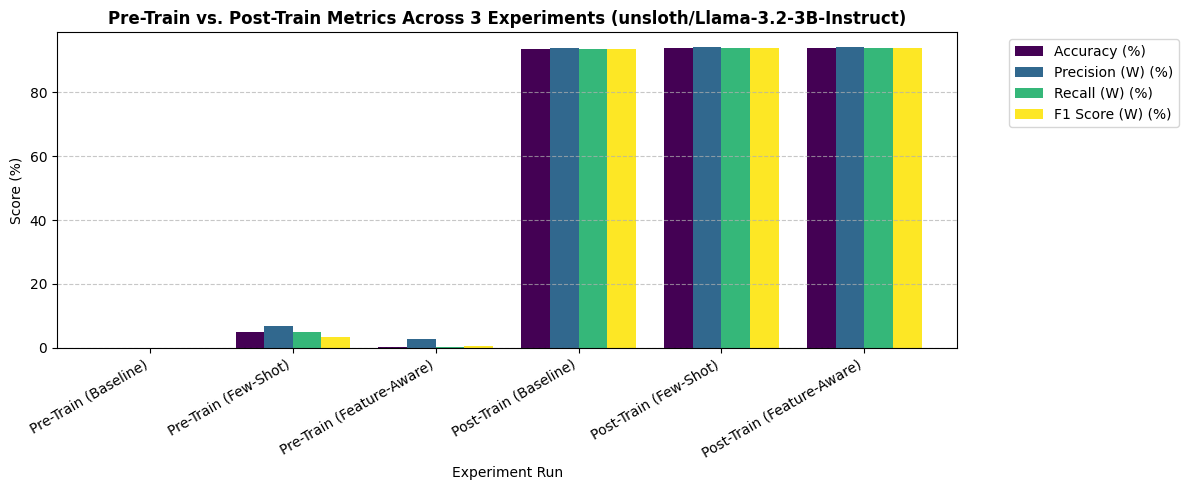

Saved performance chart to '/content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/llama_3_2_3b_banking_full10k_seed42_metrics_chart.png'.


In [12]:
import pandas as pd
from tabulate import tabulate
import matplotlib.pyplot as plt
import os
import json
import time

comparison_rows = []
for key, m in master_results.items():
    comparison_rows.append({
        "Experiment Run": key,
        "Accuracy (%)": round(m["Accuracy"] * 100, 2),
        "Precision (W) (%)": round(m["Precision (Weighted)"] * 100, 2),
        "Recall (W) (%)": round(m["Recall (Weighted)"] * 100, 2),
        "F1 Score (W) (%)": round(m["F1 (Weighted)"] * 100, 2),
        "Macro F1 (%)": round(m["F1 (Macro)"] * 100, 2),
        "Eval Time (s)": round(m.get("Eval Time (s)", 0.0), 1),
        "Eval Time": m.get("Eval Time (Formatted)", f"{m.get('Eval Time (s)', 0.0):.1f}s"),
        "Peak VRAM (GB)": round(m.get("Peak VRAM Allocated (GB)", 0.0), 2)
    })

df_master = pd.DataFrame(comparison_rows)

print("\n" + "="*115)
print(f"MASTER EVALUATION REPORT: {MODEL_NAME} on Banking77 (10,003 Train / 0 Val / 3,080 Test | Seed 42)")
print("="*115)
print(tabulate(df_master, headers="keys", tablefmt="fancy_grid", showindex=False))

# Calculate Improvement Deltas
df_master["State"] = df_master["Experiment Run"].apply(lambda x: "Pre" if "Pre" in x else "Post")
df_master["Strategy"] = df_master["Experiment Run"].apply(lambda x: x.split("(")[1].replace(")", "").strip() if "(" in x else x)

print("\n" + "="*115)
print("EXPERIMENT PERFORMANCE & TIMING DELTAS (POST-TRAIN VS. PRE-TRAIN)")
print("="*115)
for strat in ["Baseline", "Few-Shot", "Feature-Aware"]:
    pre_rows = df_master[(df_master["Strategy"] == strat) & (df_master["State"] == "Pre")]
    post_rows = df_master[(df_master["Strategy"] == strat) & (df_master["State"] == "Post")]

    if len(pre_rows) > 0 and len(post_rows) > 0:
        pre = pre_rows.iloc[0]
        post = post_rows.iloc[0]

        acc_delta = post["Accuracy (%)"] - pre["Accuracy (%)"]
        f1_delta = post["F1 Score (W) (%)"] - pre["F1 Score (W) (%)"]
        macro_delta = post["Macro F1 (%)"] - pre["Macro F1 (%)"]

        print(f"• Strategy: {strat.upper()}")
        print(f"    - Accuracy:        {pre['Accuracy (%)']:.2f}% -> {post['Accuracy (%)']:.2f}% (Gain: {acc_delta:+.2f}%)")
        print(f"    - Weighted F1:     {pre['F1 Score (W) (%)']:.2f}% -> {post['F1 Score (W) (%)']:.2f}% (Gain: {f1_delta:+.2f}%)")
        print(f"    - Macro F1:        {pre['Macro F1 (%)']:.2f}% -> {post['Macro F1 (%)']:.2f}% (Gain: {macro_delta:+.2f}%)")
        print(f"    - Pre-Eval Time:   {pre['Eval Time']} ({pre['Eval Time (s)']}s) | Peak VRAM: {pre['Peak VRAM (GB)']} GB")
        print(f"    - Post-Eval Time:  {post['Eval Time']} ({post['Eval Time (s)']}s) | Peak VRAM: {post['Peak VRAM (GB)']} GB\n")

# Load Training Hardware Stats
training_stats_file = os.path.join(CHECKPOINT_DIR, "training_hardware_and_time.json")
training_stats = {}
if os.path.exists(training_stats_file):
    try:
        with open(training_stats_file, "r") as f:
            training_stats = json.load(f)
    except Exception:
        pass

# Build Master Hardware and Computation Footprint Table
pre_time_sec = sum(m.get("Eval Time (s)", 0.0) for k, m in master_results.items() if "Pre-Train" in k)
post_time_sec = sum(m.get("Eval Time (s)", 0.0) for k, m in master_results.items() if "Post-Train" in k)
train_time_sec = training_stats.get("training_time_seconds", 0.0)
total_wall_sec = pre_time_sec + train_time_sec + post_time_sec

pre_vram = max((m.get("Peak VRAM Allocated (GB)", 0.0) for k, m in master_results.items() if "Pre-Train" in k), default=0.0)
post_vram = max((m.get("Peak VRAM Allocated (GB)", 0.0) for k, m in master_results.items() if "Post-Train" in k), default=0.0)
train_vram = training_stats.get("peak_vram_allocated_gb", 0.0)

hardware_summary = {
    "Model Architecture": MODEL_NAME,
    "Pre-Train Eval Time": time.strftime("%H:%M:%S", time.gmtime(pre_time_sec)),
    "Pre-Train Eval (s)": round(pre_time_sec, 1),
    "Pre-Train Peak VRAM (GB)": round(pre_vram, 2),
    "QLoRA Training Time": training_stats.get("training_time_formatted", time.strftime("%H:%M:%S", time.gmtime(train_time_sec))),
    "QLoRA Training (s)": round(train_time_sec, 1),
    "Training Peak VRAM (GB)": round(train_vram, 2),
    "Post-Train Eval Time": time.strftime("%H:%M:%S", time.gmtime(post_time_sec)),
    "Post-Train Eval (s)": round(post_time_sec, 1),
    "Post-Train Peak VRAM (GB)": round(post_vram, 2),
    "Total Pipeline Wall Time": time.strftime("%H:%M:%S", time.gmtime(total_wall_sec)),
    "Total Wall Time (s)": round(total_wall_sec, 1),
}

df_hw = pd.DataFrame([hardware_summary])
print("\n" + "="*115)
print(f"HARDWARE & COMPUTATIONAL FOOTPRINT SUMMARY: {MODEL_NAME}")
print("="*115)
print(tabulate(df_hw, headers="keys", tablefmt="fancy_grid", showindex=False))

# Save Summaries to CSV & JSON
csv_filename = os.path.join(CHECKPOINT_DIR, f"{MODEL_SLUG}_master_metrics_summary.csv")
df_master.to_csv(csv_filename, index=False)
print(f"Saved complete metrics summary to '{csv_filename}'.")

hw_csv_filename = os.path.join(CHECKPOINT_DIR, f"{MODEL_SLUG}_hardware_and_compute_summary.csv")
df_hw.to_csv(hw_csv_filename, index=False)
print(f"Saved hardware & computational footprint summary to '{hw_csv_filename}'.")

hw_json_filename = os.path.join(CHECKPOINT_DIR, f"{MODEL_SLUG}_hardware_and_compute_summary.json")
with open(hw_json_filename, "w") as f:
    json.dump({
        "metrics": df_master.to_dict(orient="records"),
        "hardware_footprint": hardware_summary,
        "training_details": training_stats
    }, f, indent=2)
print(f"Saved complete JSON execution profile to '{hw_json_filename}'.")

# Side-by-Side Visualization Bar Chart
try:
    fig, ax = plt.subplots(figsize=(12, 5))
    df_plot = df_master.set_index("Experiment Run")[["Accuracy (%)", "Precision (W) (%)", "Recall (W) (%)", "F1 Score (W) (%)"]]
    df_plot.plot(kind="bar", ax=ax, colormap="viridis", width=0.8)
    plt.title(f"Pre-Train vs. Post-Train Metrics Across 3 Experiments ({MODEL_NAME})", fontsize=12, fontweight="bold")
    plt.ylabel("Score (%)")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    chart_path = os.path.join(CHECKPOINT_DIR, f"{MODEL_SLUG}_metrics_chart.png")
    plt.savefig(chart_path, dpi=300)
    plt.show()
    print(f"Saved performance chart to '{chart_path}'.")
except Exception as e:
    print(f"Plotting skipped: {e}")


## 13. Storing & Exporting Fine-Tuned Model Weights
Persists LoRA adapters and tokenizers to:
1. **Local disk:** `llama_3_2_3b_banking_full10k_seed42_final`
2. **Google Drive (Colab):** `/content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/final_adapter`
3. **Kaggle Output:** `/kaggle/working/`

In [13]:
# 1. Local Adapter Export
LOCAL_SAVE_PATH = "llama_3_2_3b_banking_full10k_seed42_final"
model.save_pretrained(LOCAL_SAVE_PATH)
tokenizer.save_pretrained(LOCAL_SAVE_PATH)
print(f"Saved LoRA adapter weights locally to: {LOCAL_SAVE_PATH}")

# 2. Google Drive Export Status
print(f"Current persistent checkpoint path: {FINAL_ADAPTER_DIR}")

Unsloth: Restored added_tokens_decoder metadata in llama_3_2_3b_banking_full10k_seed42_final/tokenizer_config.json.


Saved LoRA adapter weights locally to: llama_3_2_3b_banking_full10k_seed42_final
Current persistent checkpoint path: /content/drive/MyDrive/NLP_Checkpoints/llama_3_2_3b_banking_full10k_seed42/final_adapter


## 14. Interactive Gradio Web Demonstration
Provides an interactive web application allowing users to input arbitrary customer banking queries, select one of the 3 prompting methods, and inspect predictions alongside extracted domain feature profiles.


In [14]:
# import gradio as gr

# FastLanguageModel.for_inference(model)

# def predict_banking_query(query_text, strategy):
#     if not query_text.strip():
#         return "Please input a customer banking query to analyze.", ""

#     strat_key = strategy.lower().replace("-", "_").replace(" ", "_")
#     prompt = create_prompt(query_text, strategy=strat_key)
#     messages = [{"role": "user", "content": prompt}]
#     inputs = tokenizer.apply_chat_template(
#         messages,
#         tokenize=True,
#         add_generation_prompt=True,
#         return_tensors="pt"
#     ).to("cuda")

#     with torch.no_grad():
#         outputs = model.generate(
#             input_ids=inputs,
#             max_new_tokens=15,
#             temperature=0.1,
#             do_sample=False
#         )

#     gen_text = tokenizer.decode(outputs[0][inputs.shape[1]:], skip_special_tokens=True).strip()
#     predicted_label = parse_prediction(gen_text, BANKING77_LABELS)

#     feat = extract_banking_features(query_text)
#     feature_card = (
#         f"Financial Entities Detected: {', '.join(feat['entities'])}\n"
#         f"Action / Problem Indicators: {', '.join(feat['actions'])}\n"
#         f"Query Length Profile: {feat['word_count']} words"
#     )
#     return predicted_label, feature_card

# demo = gr.Interface(
#     fn=predict_banking_query,
#     inputs=[
#         gr.Textbox(
#             lines=4,
#             placeholder="Enter customer service query here...",
#             label="Customer Banking Query",
#             value="I ordered a replacement card two weeks ago but it still hasn't arrived. How can I track the delivery?"
#         ),
#         gr.Radio(
#             choices=["Baseline", "Few-Shot", "Feature-Aware"],
#             value="Baseline",
#             label="Prompting Strategy"
#         )
#     ],
#     outputs=[
#         gr.Textbox(label="Predicted Banking Intent (Banking77 Taxonomy)", lines=2),
#         gr.Textbox(label="Domain Feature Profile", lines=4)
#     ],
#     title="Banking Customer Intent Classification Assistant",
#     description="Fine-tuned on Llama 3.2 3B Instruct with Unsloth & QLoRA on the Banking77 benchmark across 77 fine-grained intent classes."
# )

# demo.launch(share=True, debug=False)
